In [3]:
import os
import json
from pathlib import Path

import pandas as pd


ROOT = Path("/scratch/ml9715/ML-P2-Sam2/outputs/evaluations")


def load_json(path: Path) -> dict:
    with path.open("r") as f:
        return json.load(f)


# ----------------------------
# 1) One row per JSON (aggregate + metadata)
# ----------------------------
rows = []

for eval_dir in sorted([p for p in ROOT.iterdir() if p.is_dir()]):
    eval_type = eval_dir.name

    for json_path in sorted(eval_dir.rglob("*.json")):
        data = load_json(json_path)

        agg = data.get("aggregate_results", {}) or {}
        meta = data.get("run_metadata", {}) or {}

        row = {
            "eval_type": eval_type,
            "json_file": json_path.name,
            "json_path": str(json_path),

            # aggregate_results (prefix to avoid collisions)
            **{f"agg_{k}": v for k, v in agg.items()},

            # run_metadata (prefix to avoid collisions)
            **{f"meta_{k}": v for k, v in meta.items()},
        }
        rows.append(row)

df_aggregate = pd.DataFrame(rows).set_index("json_file").sort_index()

print("df_aggregate shape:", df_aggregate.shape)
display(df_aggregate.head())


# ----------------------------
# 2) Optional: per-bone results in a *long* dataframe (one row per json x bone)
# ----------------------------
bone_rows = []

for eval_dir in sorted([p for p in ROOT.iterdir() if p.is_dir()]):
    eval_type = eval_dir.name

    for json_path in sorted(eval_dir.rglob("*.json")):
        data = load_json(json_path)
        per_bone = data.get("per_bone_results", {}) or {}
        meta = data.get("run_metadata", {}) or {}

        for bone_name, bone_metrics in per_bone.items():
            bone_rows.append({
                "eval_type": eval_type,
                "json_file": json_path.name,
                "json_path": str(json_path),
                "bone": bone_name,
                **bone_metrics,
                **{f"meta_{k}": v for k, v in meta.items()},
            })

df_per_bone = pd.DataFrame(bone_rows).set_index(["json_file", "bone"]).sort_index()

print("df_per_bone shape:", df_per_bone.shape)
display(df_per_bone.head())


df_aggregate shape: (56, 22)


,eval_type,json_path,agg_num_total_cases,agg_num_successful_cases,agg_num_failed_cases,agg_dice_mean,agg_dice_std,agg_dice_min,agg_dice_max,agg_iou_mean,...,agg_iou_max,agg_hausdorff_mean,agg_hausdorff_std,agg_hausdorff_min,agg_hausdorff_max,meta_timestamp,meta_inference_mode,meta_strategy,meta_propagation,meta_model_checkpoint
json_file,,,,,,,,,,,,,,,,,,,,,
1_cond_frames.json,num_conditioned_frames,/scratch/ml9715/ML-P2-Sam2/outputs/evaluations...,500,491,9,0.829781,0.110955,0.467162,0.974315,0.761764,...,0.951787,5.598402,5.868044,0.500000,33.546089,20251215_114439,single,first_last_middle,forward,./src/base_sam2/sam2/checkpoints/sam2.1_hiera_...
2_cond_frames.json,num_conditioned_frames,/scratch/ml9715/ML-P2-Sam2/outputs/evaluations...,500,491,9,0.831615,0.128243,0.046073,0.978520,0.769212,...,0.958387,5.655121,6.073489,0.500000,44.887268,20251215_114442,single,first_last_middle,forward,./src/base_sam2/sam2/checkpoints/sam2.1_hiera_...
9_prompts.json,preprocessing,/scratch/ml9715/ML-P2-Sam2/outputs/evaluations...,500,491,9,0.856934,0.101753,0.000000,1.000000,0.807105,...,1.000000,4.268463,4.000658,0.000000,25.555233,20251217_125758,single,baseline,forward,./src/base_sam2/sam2/checkpoints/sam2.1_hiera_...
base.json,model_sizes,/scratch/ml9715/ML-P2-Sam2/outputs/evaluations...,500,491,9,0.813303,0.119952,0.285621,0.983896,0.747831,...,0.968583,6.922276,6.169312,0.391613,34.083160,20251215_130502,single,first_last_middle,forward,./src/base_sam2/checkpoints/sam2.1_hiera_base_...
baseline.json,baseline,/scratch/ml9715/ML-P2-Sam2/outputs/evaluations...,10,0,10,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,20251215_001150,single,first_last_middle,forward,./src/base_sam2/checkpoints/sam2.1_hiera_small.pt


df_per_bone shape: (606, 22)


eval_type  \
json_file          bone                                
1_cond_frames.json clavicula  num_conditioned_frames   
                   femur      num_conditioned_frames   
                   hip        num_conditioned_frames   
                   humerus    num_conditioned_frames   
                   rib        num_conditioned_frames   

                                                                      json_path  \
json_file          bone                                                           
1_cond_frames.json clavicula  /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   
                   femur      /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   
                   hip        /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   
                   humerus    /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   
                   rib        /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   

                              num_total_cases  num_successful_cases  \
json_file          bone                                               
1_cond_frames.json clavicula               50                    50   
                   femur                   50                    50   
                   hip                     50                    50   
                   humerus                 50                    50   
                   rib                     49                    49   

                              num_failed_cases  dice_mean  dice_std  dice_min  \
json_file          bone                                                         
1_cond_frames.json clavicula                 0   0.883382  0.057668  0.648321   
                   femur                     0   0.945582  0.021564  0.856440   
                   hip                       0   0.921844  0.039416  0.783124   
                   humerus                   0   0.877303  0.059003  0.730582   
                   rib                       0   0.785320  0.109137  0.467162   

                              dice_max  iou_mean  ...   iou_max  \
json_file          bone                           ...             
1_cond_frames.json clavicula  0.956752  0.833793  ...  0.917729   
                   femur      0.971408  0.912986  ...  0.948354   
                   hip        0.959344  0.873002  ...  0.923428   
                   humerus    0.958475  0.843432  ...  0.928782   
                   rib        0.929571  0.688355  ...  0.871848   

                              hausdorff_mean  hausdorff_std  hausdorff_min  \
json_file          bone                                                      
1_cond_frames.json clavicula        3.033087       2.152827       0.978860   
                   femur            2.091648       1.011858       1.186047   
                   hip              3.549750       3.083667       0.500000   
                   humerus          2.288814       2.320654       0.750000   
                   rib              5.231222       6.648477       1.059896   

                              hausdorff_max   meta_timestamp  \
json_file          bone                                        
1_cond_frames.json clavicula      12.823523  20251215_114439   
                   femur           7.016035  20251215_114439   
                   hip            14.274743  20251215_114439   
                   humerus        15.279977  20251215_114439   
                   rib            23.856606  20251215_114439   

                              meta_inference_mode      meta_strategy  \
json_file          bone                                                
1_cond_frames.json clavicula               single  first_last_middle   
                   femur                   single  first_last_middle   
                   hip                     single  first_last_middle   
                   humerus                 single  first_last_middle   
                   rib                     single  first_last_middle   

                             me

In [4]:
df_model_sizes = df_aggregate[df_aggregate["eval_type"] == "memory_bank"]
pd.set_option("display.max_columns", None)
print(df_model_sizes)

                         eval_type  \
json_file                            
repeated_4_5.json      memory_bank   
repeated_5.json        memory_bank   
repeated_5_5.json      memory_bank   
sliced_0.json          memory_bank   
sliced_1.json          memory_bank   
sliced_2.json          memory_bank   
sliced_3.json          memory_bank   
sliced_4.json          memory_bank   
sliced_5.json          memory_bank   
sliced_custom_1.json   memory_bank   
sliced_custom_2.json   memory_bank   
sliced_custom_3.json   memory_bank   
sliced_custom_4.json   memory_bank   
sliced_special_1.json  memory_bank   
sliced_special_2.json  memory_bank   
sliced_special_3.json  memory_bank   
sliced_special_4.json  memory_bank   

                                                               json_path  \
json_file                                                                  
repeated_4_5.json      /scratch/ml9715/ML-P2-Sam2/outputs/evaluations...   
repeated_5.json        /scratch/ml9715/ML-P2-Sam2

/tmp/ipykernel_3415581/3355365604.py:83: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "-^" (-> linestyle='-'). The keyword argument will take precedence.
  line3 = ax2.errorbar(thresholds, hd_means, yerr=hd_sem, label='Hausdorff Dist. (95%)',


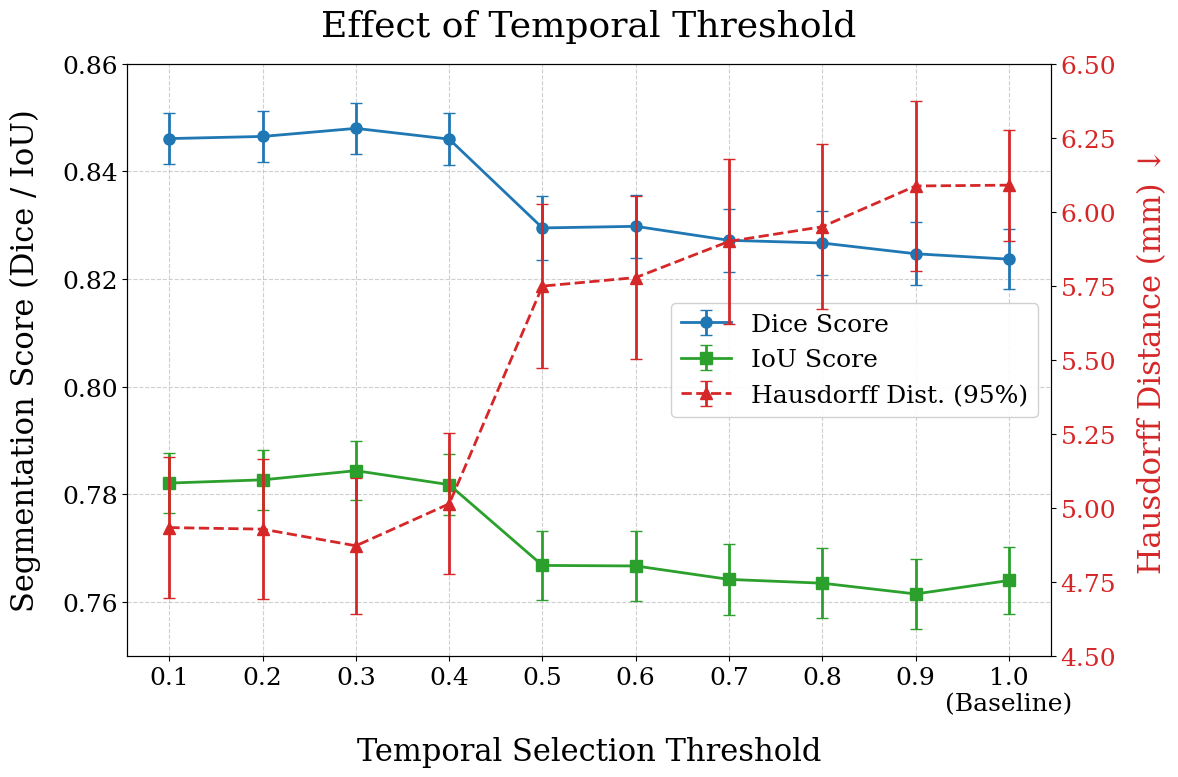

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. GLOBAL SETTINGS ---
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 14,
    'axes.titlesize': 26,
    'axes.labelsize': 22,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'figure.titlesize': 30
})

# --- 2. DATA ENTRY ---
# Existing data
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
dice_means = [0.8461, 0.8465, 0.8480, 0.8460, 0.8295, 0.8298, 0.8272, 0.8267, 0.8247]
iou_means  = [0.7821, 0.7827, 0.7844, 0.7818, 0.7668, 0.7667, 0.7642, 0.7635, 0.7615]
hd_means   = [4.9332, 4.9280, 4.8718, 5.0136, 5.7490, 5.7778, 5.9000, 5.9496, 6.0872]

dice_std = [0.1056, 0.1053, 0.1051, 0.1068, 0.1302, 0.1289, 0.1310, 0.1300, 0.1304]
iou_std  = [0.1231, 0.1228, 0.1227, 0.1247, 0.1429, 0.1427, 0.1445, 0.1434, 0.1439]
hd_std   = [5.2644, 5.2574, 5.1087, 5.2677, 6.1216, 6.1053, 6.1925, 6.1781, 6.3429]

# --- ADD BASELINE (1.0) ---
thresholds.append(1.0)

# Provided Baseline Stats
b_dice_m = 0.8237
b_dice_s = 0.1245
b_iou_m = 0.7640
b_iou_s = 0.1369
b_hd_m = 6.09
b_hd_s = 4.1578

dice_means.append(b_dice_m)
iou_means.append(b_iou_m)
hd_means.append(b_hd_m)

dice_std.append(b_dice_s)
iou_std.append(b_iou_s)
hd_std.append(b_hd_s)

# --- RECALCULATE SEM ---
N = 491
dice_sem = [s / np.sqrt(N) for s in dice_std]
iou_sem  = [s / np.sqrt(N) for s in iou_std]
hd_sem   = [s / np.sqrt(N) for s in hd_std]

# --- 3. PLOTTING ---
fig, ax1 = plt.subplots(figsize=(12, 8))

ax1.grid(True, which='major', linestyle='--', alpha=0.6)

color_dice = '#1f77b4' 
color_iou  = '#2ca02c' 

# Plot Dice
line1 = ax1.errorbar(thresholds, dice_means, yerr=dice_sem, label='Dice Score',
                     fmt='-o', color=color_dice, linewidth=2, capsize=4, markersize=8)

# Plot IoU
line2 = ax1.errorbar(thresholds, iou_means, yerr=iou_sem, label='IoU Score',
                     fmt='-s', color=color_iou, linewidth=2, capsize=4, markersize=8)

ax1.set_xlabel('Temporal Selection Threshold', labelpad=15)
ax1.set_ylabel('Segmentation Score (Dice / IoU)', labelpad=15)
ax1.set_xticks(thresholds)

# --- CUSTOM LABELS ---
# Mark 1.0 specifically as (Baseline)
xtick_labels = [str(t) if t != 1.0 else "1.0\n(Baseline)" for t in thresholds]
ax1.set_xticklabels(xtick_labels)

ax1.set_ylim(0.75, 0.86) 

# --- 4. RIGHT AXIS ---
ax2 = ax1.twinx() 
color_hd = '#d62728' 

line3 = ax2.errorbar(thresholds, hd_means, yerr=hd_sem, label='Hausdorff Dist. (95%)',
                     fmt='-^', color=color_hd, linewidth=2, linestyle='--', capsize=4, markersize=8)

ax2.set_ylabel('Hausdorff Distance (mm) ↓', labelpad=15, color=color_hd)
ax2.tick_params(axis='y', labelcolor=color_hd)

ax2.set_ylim(4.5, 6.5)

# --- 5. LEGEND & LAYOUT ---
lines = [line1, line2, line3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True, fancybox=True, framealpha=0.9)

plt.title('Effect of Temporal Threshold', pad=20)
plt.tight_layout()

plt.show()

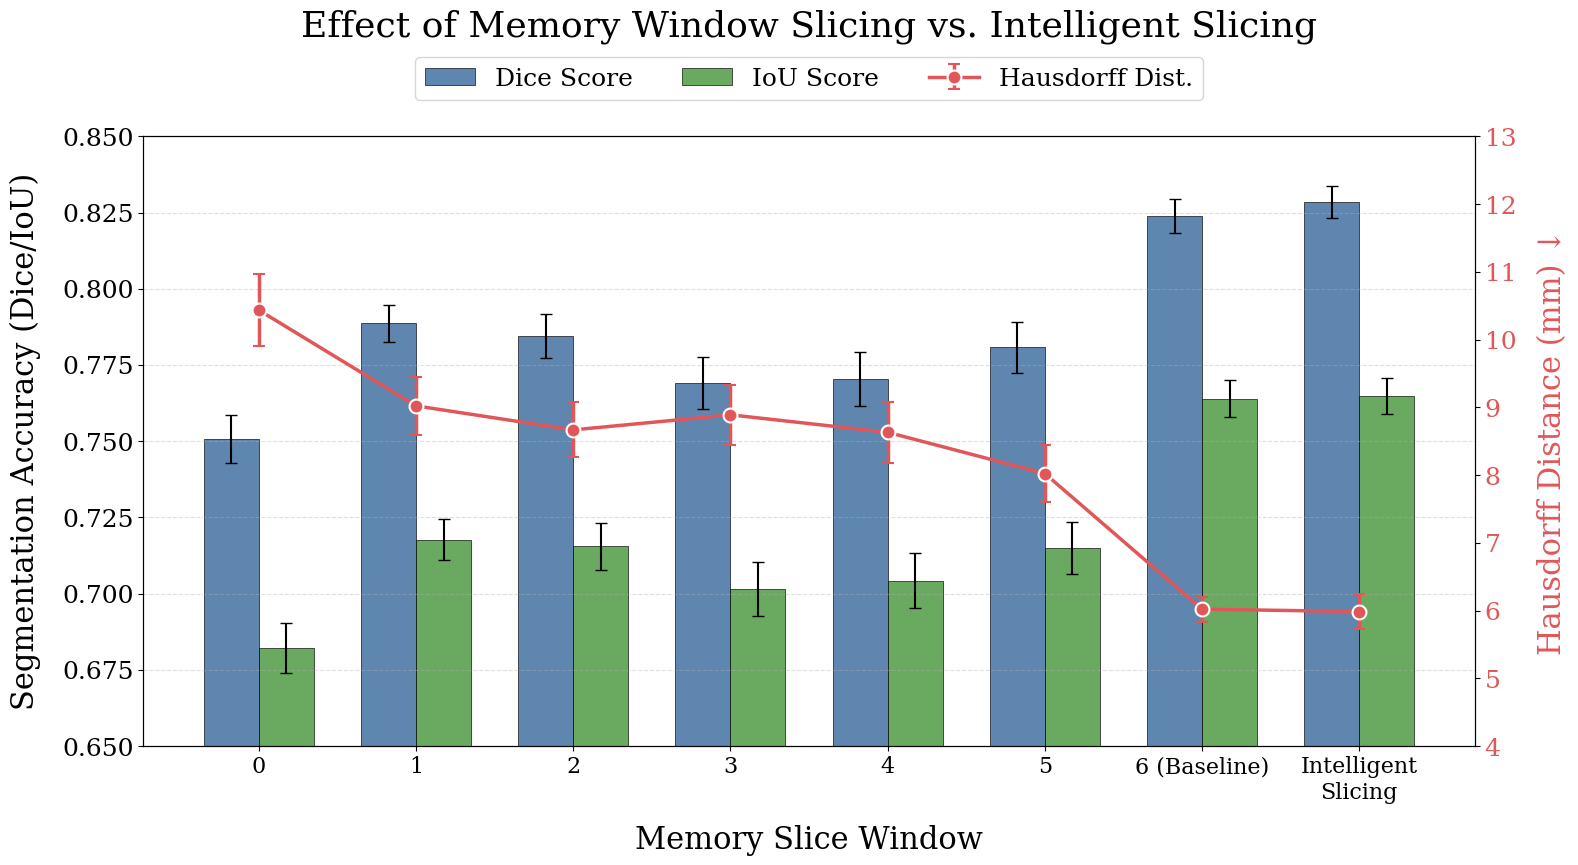

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# --- 1. GLOBAL SETTINGS ---
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 14,
    'axes.titlesize': 26,
    'axes.labelsize': 22,
    'xtick.labelsize': 16,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'figure.titlesize': 30
})



# --- 2. DATA PREPARATION ---
# Added 'Intelligent Slicing' to labels
labels = ['0', '1', '2', '3', '4', '5', '6 (Baseline)', 'Intelligent\nSlicing']
x = np.arange(len(labels))

# Dice Data (Added 0.828418)
dice_means = [0.750674, 0.788704, 0.784548, 0.769154, 0.770496, 0.7808, 0.823704, 0.828418]
dice_std   = [0.174124, 0.135951, 0.163566, 0.192104, 0.196883, 0.1853, 0.124498, 0.115857]

# IoU Data (Added 0.764734)
iou_means = [0.682032, 0.717634, 0.715464, 0.701499, 0.704242, 0.7148, 0.763987, 0.764734]
iou_std   = [0.183396, 0.150953, 0.172374, 0.195753, 0.200252, 0.1906, 0.136927, 0.132231]

# Hausdorff Data (Added 5.984896)
hd_means = [10.434524, 9.021048, 8.666169, 8.888805, 8.630682, 8.0220, 6.0198, 5.984896]
hd_std   = [11.953107, 9.676470, 9.097713, 9.849772, 10.113691, 9.526, 4.157843, 5.737408]

# SEM (N=500 for all cases)
N = 500
dice_sem = [s / np.sqrt(N) for s in dice_std]
iou_sem  = [s / np.sqrt(N) for s in iou_std]
hd_sem   = [s / np.sqrt(N) for s in hd_std]

# --- 3. PLOTTING SETUP ---
fig, ax1 = plt.subplots(figsize=(16, 9))
bar_width = 0.35

# --- 4. PLOT BARS (Left Axis - Dice & IoU) ---
rects1 = ax1.bar(x - bar_width/2, dice_means, bar_width, yerr=dice_sem,
                 label='Dice Score', color='#4e79a7', capsize=4, alpha=0.9,
                 edgecolor='black', linewidth=0.5)

rects2 = ax1.bar(x + bar_width/2, iou_means, bar_width, yerr=iou_sem,
                 label='IoU Score', color='#59a14f', capsize=4, alpha=0.9,
                 edgecolor='black', linewidth=0.5)

ax1.set_xlabel('Memory Slice Window', labelpad=15)
ax1.set_ylabel('Segmentation Accuracy (Dice/IoU)', labelpad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_ylim(0.65, 0.85) 
ax1.grid(axis='y', linestyle='--', alpha=0.4)

# --- 5. PLOT LINE (Right Axis - Hausdorff) ---
ax2 = ax1.twinx()
ax2.errorbar(x, hd_means, yerr=hd_sem, label='Hausdorff Dist.',
             fmt='-o', color='#e15759', linewidth=2.5, capsize=4,
             markersize=10, markeredgecolor='white', markeredgewidth=1.5)

ax2.set_ylabel('Hausdorff Distance (mm) ↓', labelpad=15, color='#e15759')
ax2.tick_params(axis='y', labelcolor='#e15759')
ax2.set_ylim(4, 13)

# --- 6. LEGEND ---
bars_leg = [rects1, rects2]
line_leg, line_labels = ax2.get_legend_handles_labels()

ax1.legend(bars_leg + line_leg, [b.get_label() for b in bars_leg] + line_labels,
           loc='upper center', bbox_to_anchor=(0.5, 1.15),
           frameon=True, fancybox=True, shadow=False, ncol=3)

plt.title('Effect of Memory Window Slicing vs. Intelligent Slicing', y=1.15)
plt.tight_layout()
plt.savefig('slicing_comparison_plot.png')

/tmp/ipykernel_3415581/996220548.py:49: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax1.bxp(bxp_dice, positions=pos_dice, widths=0.2, patch_artist=True,
/tmp/ipykernel_3415581/996220548.py:53: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax1.bxp(bxp_iou, positions=pos_iou, widths=0.2, patch_artist=True,
/tmp/ipykernel_3415581/996220548.py:63: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax2.bxp(bxp_haus, positions=pos_haus, widths=0.2, patch_artist=True,


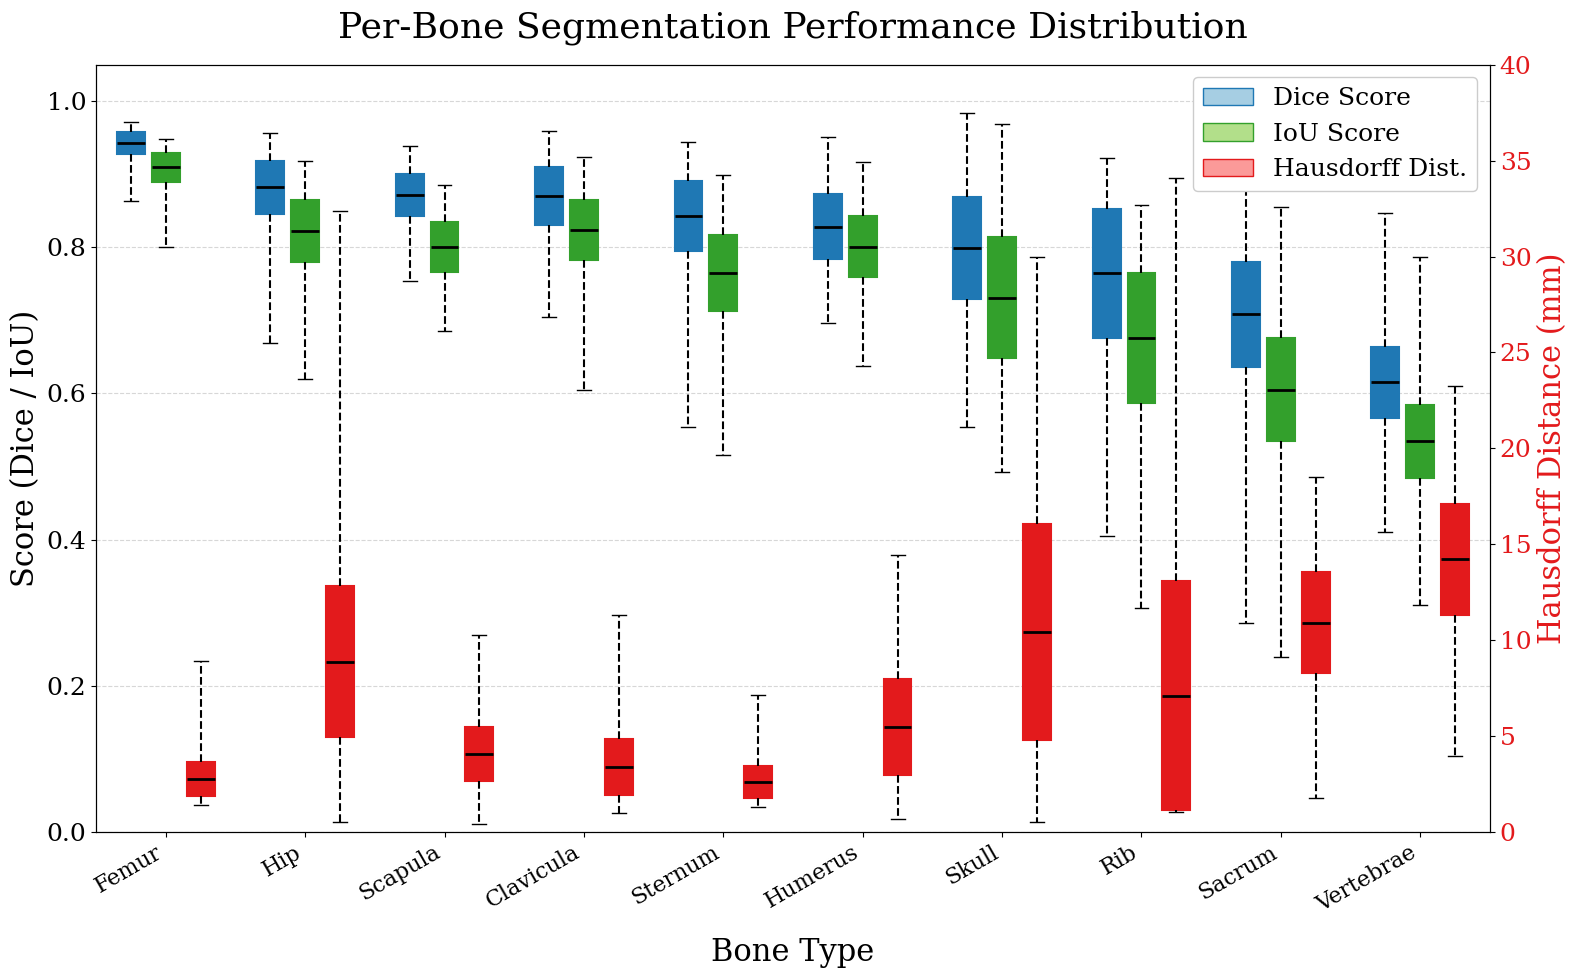

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# --- 2. DATA PREPARATION ---
data_full = {
    "sacrum": {"dice": {"mean": 0.7084, "std": 0.1064, "min": 0.2856, "max": 0.9185}, "iou": {"mean": 0.6051, "std": 0.1042, "min": 0.2395, "max": 0.8552}, "haus": {"mean": 10.9028, "std": 3.8781, "min": 1.7322, "max": 18.4850}},
    "vertebrae": {"dice": {"mean": 0.6152, "std": 0.0714, "min": 0.4100, "max": 0.8474}, "iou": {"mean": 0.5344, "std": 0.0740, "min": 0.3098, "max": 0.7873}, "haus": {"mean": 14.1980, "std": 4.3159, "min": 3.9604, "max": 23.2414}},
    "humerus": {"dice": {"mean": 0.8284, "std": 0.0653, "min": 0.6960, "max": 0.9512}, "iou": {"mean": 0.8009, "std": 0.0619, "min": 0.6382, "max": 0.9173}, "haus": {"mean": 5.4588, "std": 3.6887, "min": 0.6458, "max": 14.4453}},
    "scapula": {"dice": {"mean": 0.8718, "std": 0.0431, "min": 0.7541, "max": 0.9382}, "iou": {"mean": 0.8002, "std": 0.0510, "min": 0.6852, "max": 0.8851}, "haus": {"mean": 4.0527, "std": 2.0878, "min": 0.3916, "max": 10.2723}},
    "clavicula": {"dice": {"mean": 0.8704, "std": 0.0579, "min": 0.7044, "max": 0.9597}, "iou": {"mean": 0.8236, "std": 0.0609, "min": 0.6049, "max": 0.9239}, "haus": {"mean": 3.3764, "std": 2.1295, "min": 0.9709, "max": 11.2978}},
    "femur": {"dice": {"mean": 0.9432, "std": 0.0224, "min": 0.8639, "max": 0.9717}, "iou": {"mean": 0.9096, "std": 0.0291, "min": 0.8011, "max": 0.9487}, "haus": {"mean": 2.7646, "std": 1.3223, "min": 1.3860, "max": 8.8887}},
    "hip": {"dice": {"mean": 0.8823, "std": 0.0540, "min": 0.6695, "max": 0.9563}, "iou": {"mean": 0.8225, "std": 0.0637, "min": 0.6203, "max": 0.9182}, "haus": {"mean": 8.8744, "std": 5.8664, "min": 0.5000, "max": 32.3794}},
    "skull": {"dice": {"mean": 0.7989, "std": 0.1031, "min": 0.5543, "max": 0.9839}, "iou": {"mean": 0.7313, "std": 0.1228, "min": 0.4918, "max": 0.9686}, "haus": {"mean": 10.4294, "std": 8.3360, "min": 0.5000, "max": 29.9496}},
    "rib": {"dice": {"mean": 0.7643, "std": 0.1305, "min": 0.4045, "max": 0.9218}, "iou": {"mean": 0.6762, "std": 0.1321, "min": 0.3056, "max": 0.8577}, "haus": {"mean": 7.0928, "std": 8.8621, "min": 1.0253, "max": 34.0832}},
    "sternum": {"dice": {"mean": 0.8428, "std": 0.0703, "min": 0.5538, "max": 0.9445}, "iou": {"mean": 0.7652, "std": 0.0774, "min": 0.5154, "max": 0.8993}, "haus": {"mean": 2.5946, "std": 1.2503, "min": 1.2676, "max": 7.1520}}
}

def make_stats(d):
    mean, std = d['mean'], d['std']
    return {
        'med': mean, 
        'q1': mean - 0.675 * std, 
        'q3': mean + 0.675 * std, 
        'whislo': d['min'], 
        'whishi': d['max'],
        'label': ''
    }

sorted_bones = sorted(data_full.keys(), key=lambda k: data_full[k]['dice']['mean'], reverse=True)
bxp_dice = [make_stats(data_full[b]['dice']) for b in sorted_bones]
bxp_iou  = [make_stats(data_full[b]['iou'])  for b in sorted_bones]
bxp_haus = [make_stats(data_full[b]['haus']) for b in sorted_bones]

# --- 3. PLOTTING ---
fig, ax1 = plt.subplots(figsize=(16, 10))

N = len(sorted_bones)
indices = np.arange(1, N + 1)
width = 0.25
pos_dice = indices - width
pos_iou  = indices
pos_haus = indices + width

med_props = dict(linestyle='-', linewidth=2, color='black')
whis_props = dict(linestyle='--', linewidth=1.5, color='black')

# LEFT AXIS: Dice & IoU
ax1.bxp(bxp_dice, positions=pos_dice, widths=0.2, patch_artist=True,
        boxprops=dict(facecolor='#a6cee3', color='#1f78b4', linewidth=1.5),
        medianprops=med_props, whiskerprops=whis_props, showfliers=False)

ax1.bxp(bxp_iou, positions=pos_iou, widths=0.2, patch_artist=True,
        boxprops=dict(facecolor='#b2df8a', color='#33a02c', linewidth=1.5),
        medianprops=med_props, whiskerprops=whis_props, showfliers=False)

ax1.set_ylabel('Score (Dice / IoU)')
ax1.set_ylim(0, 1.05)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# RIGHT AXIS: Hausdorff
ax2 = ax1.twinx()
ax2.bxp(bxp_haus, positions=pos_haus, widths=0.2, patch_artist=True,
        boxprops=dict(facecolor='#fb9a99', color='#e31a1c', linewidth=1.5),
        medianprops=med_props, whiskerprops=whis_props, showfliers=False)

ax2.set_ylabel('Hausdorff Distance (mm)', color='#e31a1c')
ax2.tick_params(axis='y', labelcolor='#e31a1c')
ax2.set_ylim(0, 40)

# --- 4. AXIS LABELS AND TICKS ---
ax1.set_xlim(0.5, N + 0.5)
ax1.set_xticks(indices)
ax1.set_xticklabels([b.title() for b in sorted_bones], rotation=30, ha='right')

# Added X-Axis Title
ax1.set_xlabel('Bone Type', labelpad=15) 

# --- 5. LEGEND & TITLE ---
legend_elements = [
    Patch(facecolor='#a6cee3', edgecolor='#1f78b4', label='Dice Score'),
    Patch(facecolor='#b2df8a', edgecolor='#33a02c', label='IoU Score'),
    Patch(facecolor='#fb9a99', edgecolor='#e31a1c', label='Hausdorff Dist.')
]
ax1.legend(handles=legend_elements, loc='upper right', frameon=True, framealpha=1.0)

plt.title('Per-Bone Segmentation Performance Distribution', pad=20)
plt.tight_layout()
plt.show()

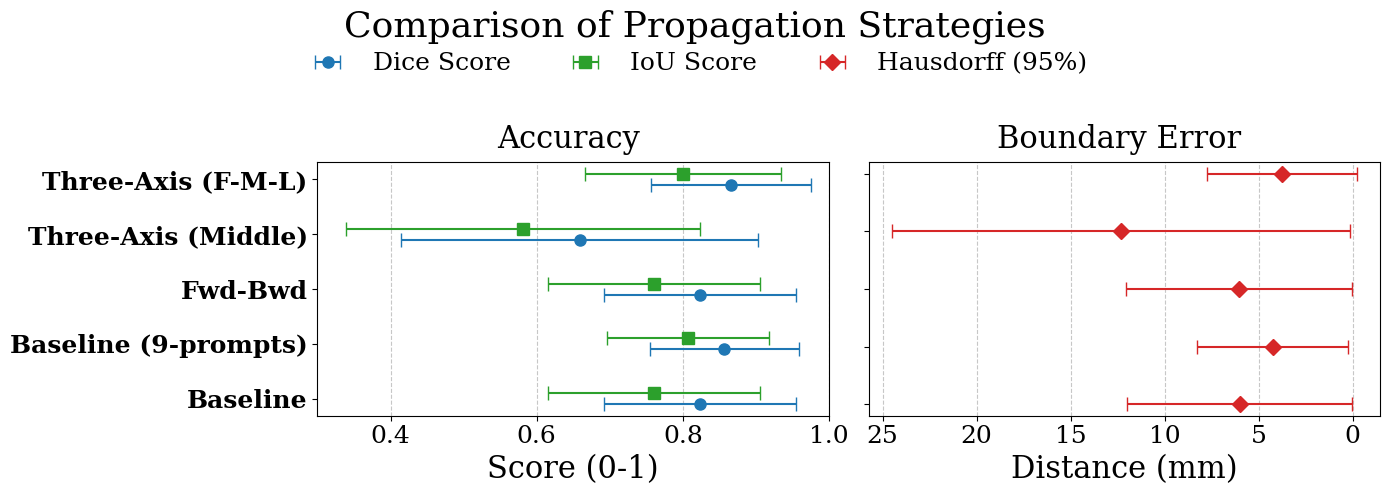

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# --- Data (ordered more logically) ---
methods = [
    "Baseline",
    "Baseline (9-prompts)",
    "Fwd-Bwd",
    "Three-Axis (Middle)",
    "Three-Axis (F-M-L)",
]
y_pos = np.arange(len(methods))

dice_m = [0.8236, 0.8569, 0.8233, 0.6592, 0.8661]
dice_s = [0.1314, 0.1018, 0.1316, 0.2444, 0.1091]

iou_m  = [0.7604, 0.8071, 0.7601, 0.5816, 0.8003]
iou_s  = [0.1448, 0.1115, 0.1450, 0.2421, 0.1340]

hd_m   = [6.02, 4.2685, 6.05, 12.33, 3.77]
hd_s   = [5.97, 4.0007, 6.01, 12.18, 3.98]

# --- Plotting ---
plt.rcParams.update({'font.family': 'serif'})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

l1 = ax1.errorbar(dice_m, y_pos, xerr=dice_s, fmt='o', label='Dice Score',
                  color='#1f77b4', capsize=5, markersize=8)
l2 = ax1.errorbar(iou_m, y_pos + 0.2, xerr=iou_s, fmt='s', label='IoU Score',
                  color='#2ca02c', capsize=5, markersize=8)

ax1.set_yticks(y_pos + 0.1)
ax1.set_yticklabels(methods, fontweight='bold')
ax1.set_xlabel('Score (0-1)')
ax1.set_title('Accuracy ', pad=10)
ax1.grid(axis='x', linestyle='--', alpha=0.7)
ax1.set_xlim(0.3, 1.0)

l3 = ax2.errorbar(hd_m, y_pos + 0.1, xerr=hd_s, fmt='D', label='Hausdorff (95%)',
                  color='#d62728', capsize=5, markersize=8)

ax2.set_yticks(y_pos + 0.1)
ax2.set_yticklabels([])
ax2.set_xlabel('Distance (mm)')
ax2.set_title('Boundary Error ', pad=10)
ax2.grid(axis='x', linestyle='--', alpha=0.7)
ax2.invert_xaxis()

# Title first
fig.suptitle("Comparison of Propagation Strategies", y=0.98)

# Legend just below the title (no overlap)
handles = [l1, l2, l3]
labels = [h.get_label() for h in handles]
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False,
           bbox_to_anchor=(0.5, 0.94))

# Reserve top space for title + legend
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()
